# Stage 2A-3：車線ごとにトラックの割合が違うとき、アルゴリズムはどう判定するか

- 3車線（K = 3）。各車線は独立した円環（車線変更なし）。Chen と同じく、**3車線をまとめて1枚のスナップショット**にして判定する
- 変えるのは**トラックの偏り方 σ だけ**
  - σ = 0：全車線でトラックの割合が同じ → 見た目は混合（1-pipe）。2A-1 の「平均の m̄」と同じ状態
  - σ = 1：トラックをできるだけ lane 3 に集める。P2 = 1/3 なら lane 3 がトラックだけ、lane 1, 2 が車だけ → 見た目は完全分離（2-pipe の形、p2 = 1/3）
  - 0 < σ < 1：部分的な分離（NGSIM の lane 3 にトラックが多いのと同じ形）。Eq.11 の3分類（1-pipe / 2-pipe / non-NE）のどれにも当てはまらない状態
- 決めたこと
  - 各車線の全体の密度は同じ（ρ）。トラックを lane 3 に寄せた分、lane 3 の車が lane 1, 2 に移る
  - 各車線の中はランダム混合の平均 m̄（2A-1 の並び方のばらつきは入れない）→ ずれの原因は**車線の偏りだけ**
  - クラスの観測速度は空間平均速度：ũ_i = Σ_k ρ_ik v_k / Σ_k ρ_ik（`ring_state` と同じ）
- §1〜4：論文形（セットP）、§5：OV スケール形（2A-1 §8 と同じ設定）

流れ：(ρ, P2, σ) → 車線ごとの (ρ1k, ρ2k) → 車線ごとの定常速度 v_k → クラス平均 ũ1, ũ2 と全体の密度 ρ1, ρ2 → Eq.7 で u* → Eq.11 で判定（ε を変える）

In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import brentq

%load_ext autoreload
%autoreload 2

ROOT = Path(os.path.abspath("../.."))   # notebooks/check → notebooks → ルート
sys.path.append(str(ROOT))

from src.ring_equilibrium import (make_paper_nominal, make_ov_nominal, true_1pipe_speed, at_speed_cap,
                                  R_eq, CAR, TRUCK)
from src.whole_pipeline import (solve_1pipe_speed, compute_min_road_share, compute_cooperation_surplus,
                                classify_traffic_regime, check_cooperation_existence)

KM_TO_MILE = 1.60934
OUT = ROOT / "results" / "stage2A3_2026-11-11"
OUT.mkdir(parents=True, exist_ok=True)

## 0. パラメータと実験条件

In [2]:
# 論文 Table 4（km/h, veh/km に換算）と Table 5：セットP
CAR_PARAMS = {'ub': 7.93 * KM_TO_MILE, 'uf': 73.55 * KM_TO_MILE, 'rhoc': 20.40 / KM_TO_MILE,
              'theta1': 8.0387 / KM_TO_MILE, 'theta2': 0.2309}
TRUCK_PARAMS = {'uf': 42.55 * KM_TO_MILE, 'rhoc': 41.74 / KM_TO_MILE}
A2, B1 = 0.4528, 2.5996
NOMINAL = make_paper_nominal(CAR_PARAMS, TRUCK_PARAMS, A2, B1)

K = 3                                     # 車線数
RHO_TOT = [20, 40, 60, 80]                # 各車線の全体の密度 (veh/km/lane)
P2_LIST = [0.1, 0.2, 1 / 3]               # トラックの割合。1/3 なら σ=1 で完全分離になる
SIGMA_LIST = np.round(np.linspace(0, 1, 11), 2)   # トラックの偏り方
EPS_LIST = [1e-6, 0.5, 1.0, 2.0]          # ε (km/h)

## 1. 部品
- `lane_split(rho, P2, sigma)`：σ から車線ごとの (ρ1k, ρ2k) を決める
  - 偏りなしのトラック密度 ρ2_eq = ρ·P2、lane 3 に入れられる最大 ρ2_max = min(ρ, K·ρ2_eq)
  - lane 3：ρ2_eq + σ·(ρ2_max − ρ2_eq)、lane 1, 2：残りを等分
- `multilane_snapshot(nominal, lanes)`：車線ごとの定常速度 v_k を解き、クラス平均速度と全体の密度を返す
  - v_k は `true_1pipe_speed`（その車線をランダム混合の平均 m̄ で解く。車だけ・トラックだけの車線もそのまま解ける）
  - 速度が解けない・上限に張り付く車線があれば NaN（判定では undefined）
- `visual_label(lanes)`：見た目の分類（混合 / 部分分離 / 完全分離）

In [3]:
def lane_split(rho, P2, sigma):
    """σ から車線ごとの (ρ1k, ρ2k) のリストを作る。最後（lane 3）にトラックを寄せる"""
    rho2_eq = rho * P2
    rho2_max = min(rho, K * rho2_eq)
    r2_3 = rho2_eq + sigma * (rho2_max - rho2_eq)
    r2_other = max((K * rho2_eq - r2_3) / (K - 1), 0.0)   # 浮動小数点で -1e-15 になるのを防ぐ
    r2_lanes = [r2_other] * (K - 1) + [r2_3]
    return [(max(rho - r2, 0.0), r2) for r2 in r2_lanes]


def multilane_snapshot(nominal, lanes):
    """
    lanes: [(ρ1k, ρ2k), ...]。車線ごとの定常速度と、スナップショットとしての値を返す
      rho1, rho2 : 全体の密度（車線の平均, veh/km/lane）
      u1_obs, u2_obs : クラスの空間平均速度 Σ_k ρ_ik v_k / Σ_k ρ_ik
    """
    v = []
    for r1, r2 in lanes:
        vk = true_1pipe_speed(nominal, r1, r2)
        if not np.isfinite(vk) or at_speed_cap(nominal, r1, r2, vk):
            vk = np.nan
        v.append(vk)
    v = np.array(v)
    r1 = np.array([l[0] for l in lanes])
    r2 = np.array([l[1] for l in lanes])
    return {'rho1': r1.mean(), 'rho2': r2.mean(),
            'u1_obs': np.sum(r1 * v) / r1.sum(), 'u2_obs': np.sum(r2 * v) / r2.sum(),
            'v_lanes': v}


def visual_label(lanes, tol=1e-9):
    """全車線が同じ構成 → 混合、全車線が1クラスだけ → 完全分離、それ以外 → 部分分離"""
    shares = [r2 / (r1 + r2) for r1, r2 in lanes]
    if max(shares) - min(shares) < tol:
        return '混合'
    if all(min(r1, r2) < tol for r1, r2 in lanes):
        return '完全分離'
    return '部分分離'


# 確認：ρ=40, P2=1/3 で σ を 0, 0.5, 1 にしたときの車線ごとの密度
for s in [0, 0.5, 1]:
    print(s, [tuple(round(x, 2) for x in l) for l in lane_split(40, 1 / 3, s)], visual_label(lane_split(40, 1 / 3, s)))

0 [(26.67, 13.33), (26.67, 13.33), (26.67, 13.33)] 混合
0.5 [(33.33, 6.67), (33.33, 6.67), (13.33, 26.67)] 部分分離
1 [(40.0, 0.0), (40.0, 0.0), (0.0, 40.0)] 完全分離


## 2. 観測データを作って、アルゴリズムを流す（論文形・セットP）
- 1つの (ρ, P2, σ) が1枚のスナップショット
- アルゴリズムは Stage 1 で検証済みの src（whole_pipeline）をそのまま使う
- **正解のラベル**は見た目がはっきりしているときだけ付ける
  - 混合（σ = 0）：s < 0 → L1、s > 0 → L2（どちらも 1-pipe）
  - 完全分離：p_i（その車線数 / K）と p_i* を比べ、両方 p_i ≥ p_i* かつ s > 0 → L3（2-pipe）、そうでなければ L4（non-NE）
  - 部分分離：論文の枠組みにラベルがない（—）

In [4]:
def build_snapshots(nominal, rho_list):
    rows = []
    for rho in rho_list:
        for P2 in P2_LIST:
            for sigma in SIGMA_LIST:
                lanes = lane_split(rho, P2, sigma)
                snap = multilane_snapshot(nominal, lanes)
                row = {'rho_tot': rho, 'P2': round(P2, 3), 'sigma': sigma, 'visual': visual_label(lanes),
                       'rho1': snap['rho1'], 'rho2': snap['rho2'],
                       'u1_obs': snap['u1_obs'], 'u2_obs': snap['u2_obs'],
                       'truck_share_lane3': lanes[-1][1] / rho}
                for k, vk in enumerate(snap['v_lanes']):
                    row[f'v_lane{k + 1}'] = vk
                # 完全分離のときの道路シェア p2 = トラックだけの車線の数 / K
                row['p2_actual'] = sum(1 for r1, r2 in lanes if r1 < 1e-9) / K if row['visual'] == '完全分離' else np.nan
                rows.append(row)
    return pd.DataFrame(rows)


def add_truth_label(df):
    """見た目がはっきりしているスナップショットだけ正解のラベルを付ける"""
    df = df.copy()
    df['label'] = '—'
    mixed = df['visual'] == '混合'
    df.loc[mixed, 'label'] = np.where(df.loc[mixed, 's'] > 0, 'L2', 'L1')
    sep = df['visual'] == '完全分離'
    p2 = df.loc[sep, 'p2_actual']
    ok = (1 - p2 >= df.loc[sep, 'p1_star']) & (p2 >= df.loc[sep, 'p2_star']) & (df.loc[sep, 's'] > 0)
    df.loc[sep, 'label'] = np.where(ok, 'L3', 'L4')
    return df


df_obs = build_snapshots(NOMINAL, RHO_TOT)
print(f"スナップショット {len(df_obs)} 枚、速度が解けない: {df_obs[['u1_obs', 'u2_obs']].isna().any(axis=1).sum()} 枚")

# Step 3a〜3c（src）
df_obs['u_1pipe'] = [solve_1pipe_speed(r['rho1'], r['rho2'], CAR_PARAMS, TRUCK_PARAMS, A2, B1, scaling='printed')
                     for _, r in df_obs.iterrows()]
df = compute_min_road_share(df_obs, CAR_PARAMS, TRUCK_PARAMS)
df = compute_cooperation_surplus(df)
df = add_truth_label(df)
df['du1'] = df['u1_obs'] - df['u_1pipe']
df['du2'] = df['u2_obs'] - df['u_1pipe']

# Step 4, 5：ε ごとに判定（src）
regimes, coop = {}, {}
for eps in EPS_LIST:
    out = check_cooperation_existence(classify_traffic_regime(df, eps_kmh=eps))
    regimes[eps], coop[eps] = out['regime'], out['coop_exists']
    df[f'regime_{eps:g}'] = out['regime']

# 確認：σ = 0（全車線同じ構成）なら ũ1 = ũ2 = u* のはず
mix = df['visual'] == '混合'
print(f"\nσ=0 での |ũ − u*| の最大値（0 のはず）: {df.loc[mix, ['du1', 'du2']].abs().max().max():.1e} km/h")
print(f"s の範囲: {df['s'].min():.4f} 〜 {df['s'].max():.4f}")
df.to_csv(OUT / "stage2A3_paper.csv", index=False, encoding='utf-8-sig')

スナップショット 132 枚、速度が解けない: 10 枚
最小道路占有を計算: 132スナップショット中、132件で計算完了
協力余剰sを計算: 132スナップショット中、132件で計算完了（うちs>0: 0件）
交通状態を判定(eps: 車 0.00, トラック 0.00 km/h): 判定対象 122件 (対象外 undefined: 10件)
      2-pipe: 0件 (0.00%)
      1-pipe: 12件 (9.84%)
      non-NE: 110件 (90.16%)
  Pcoop = 0.00% (論文: 13.83%)
  平均s: 2-pipe = nan, 1-pipe = -0.0881 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 122件
  s>0             : 0件 (0.00%)
  2-pipe          : 0件 (0.00%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 0件 (0.00%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 0件 (nan% of 2-pipe)  ← 命題1と不整合
交通状態を判定(eps: 車 0.50, トラック 0.50 km/h): 判定対象 122件 (対象外 undefined: 10件)
      2-pipe: 1件 (0.82%)
      1-pipe: 39件 (31.97%)
      non-NE: 82件 (67.21%)
  Pcoop = 0.82% (論文: 13.83%)
  平均s: 2-pipe = -0.0357, 1-pipe = -0.0751 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 122件
  s>0             : 0件 (0.00%)
  2-pipe          : 1件 (0.82%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 0件 (0.00%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 1件 (100.00% of 2-pipe)  ← 命題1と不整合
交通状態を判定(eps: 車 1.00, トラック 1.

## 3. 図：車線ごとの速度とクラス平均速度（しくみ）
- 細線：車線ごとの速度（lane 1 = lane 2 は実線、lane 3（トラックが多い車線）は点線）
- 太線：クラス平均速度 ũ1（青）、ũ2（赤）
- 黒の破線：u*、灰色の帯：u* ± 2 km/h（Chen の ε）

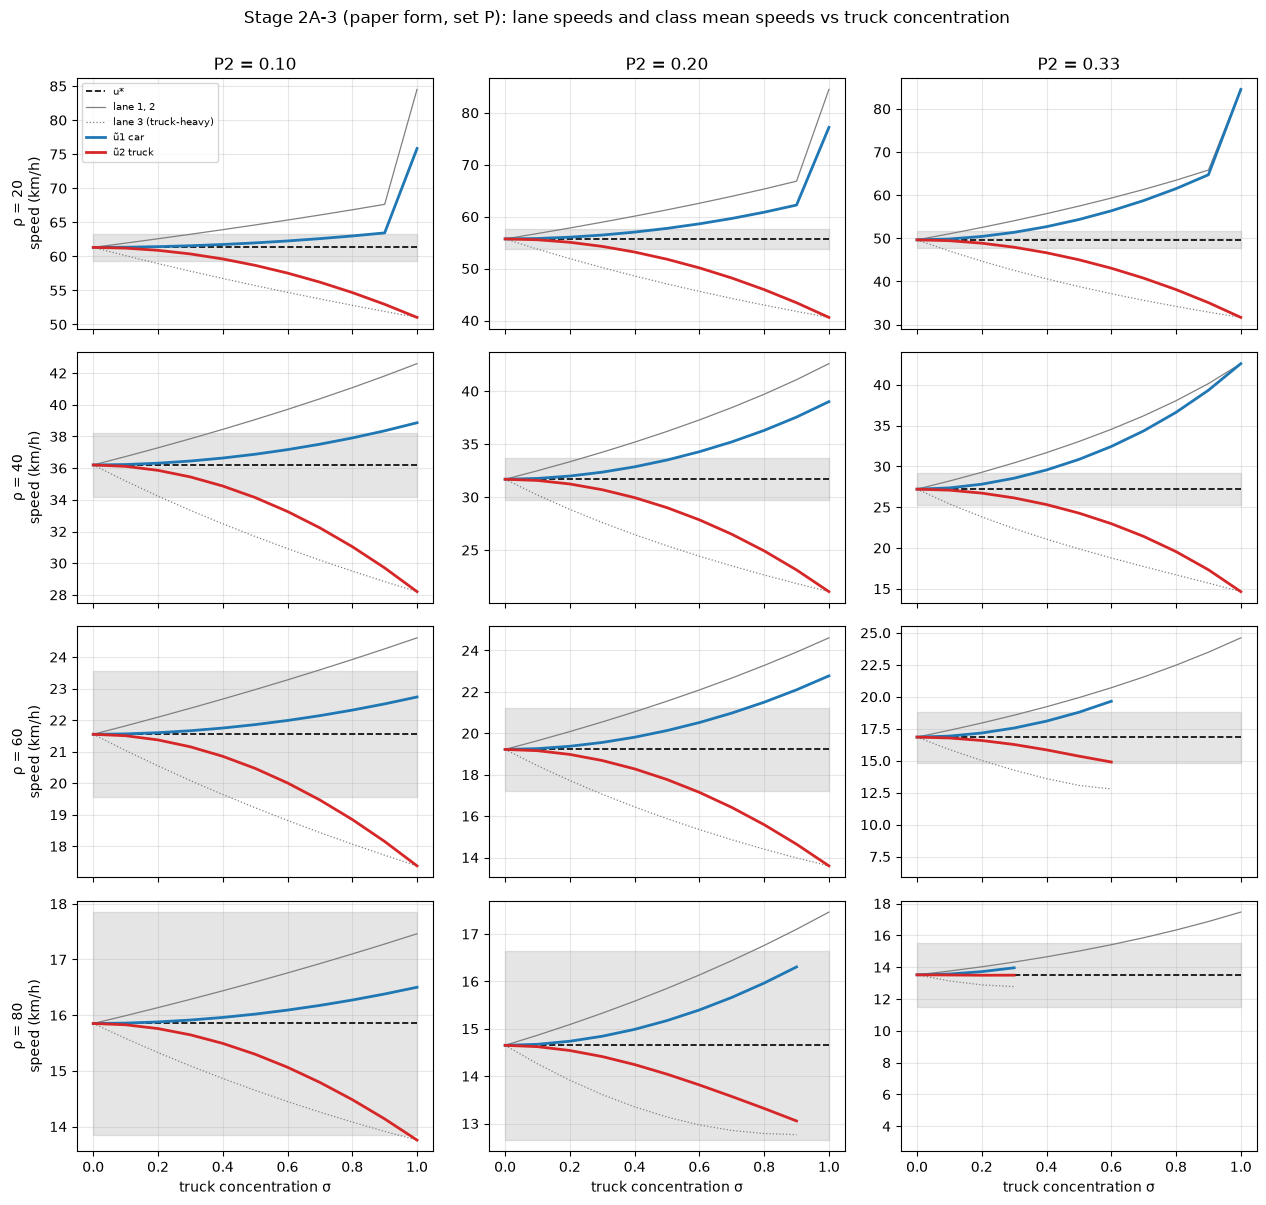

In [5]:
def plot_mechanism(df, rho_list, title, fname):
    fig, axes = plt.subplots(len(rho_list), len(P2_LIST), figsize=(4.3 * len(P2_LIST), 3.0 * len(rho_list)),
                             sharex=True)
    for a, rho in enumerate(rho_list):
        for b, P2 in enumerate(P2_LIST):
            ax = axes[a, b]
            g = df[(df['rho_tot'] == rho) & (df['P2'] == round(P2, 3))].sort_values('sigma')
            ax.fill_between(g['sigma'], g['u_1pipe'] - 2, g['u_1pipe'] + 2, color='gray', alpha=0.2)
            ax.plot(g['sigma'], g['u_1pipe'], 'k--', lw=1.2, label='u*')
            ax.plot(g['sigma'], g['v_lane1'], color='gray', lw=0.9, label='lane 1, 2')
            ax.plot(g['sigma'], g['v_lane3'], color='gray', lw=0.9, ls=':', label='lane 3 (truck-heavy)')
            ax.plot(g['sigma'], g['u1_obs'], color='tab:blue', lw=2, label='ũ1 car')
            ax.plot(g['sigma'], g['u2_obs'], color='tab:red', lw=2, label='ũ2 truck')
            if a == 0:
                ax.set_title(f"P2 = {P2:.2f}")
            if b == 0:
                ax.set_ylabel(f"ρ = {rho}\nspeed (km/h)")
            if a == len(rho_list) - 1:
                ax.set_xlabel("truck concentration σ")
            ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=150, bbox_inches='tight')
    plt.show()

plot_mechanism(df, RHO_TOT, "Stage 2A-3 (paper form, set P): lane speeds and class mean speeds vs truck concentration",
               "stage2A3_paper_mechanism.png")

## 4. 図と表：判定結果
- 図：縦 ε × 横 P2。各パネルは横軸 σ、縦軸 ρ で、色が判定（1-pipe / 2-pipe / non-NE / undefined）
- 表：**1-pipe でなくなる最小の σ**（ε ごと）。σ がこれより小さい偏りは、アルゴリズムからは混合と区別できない

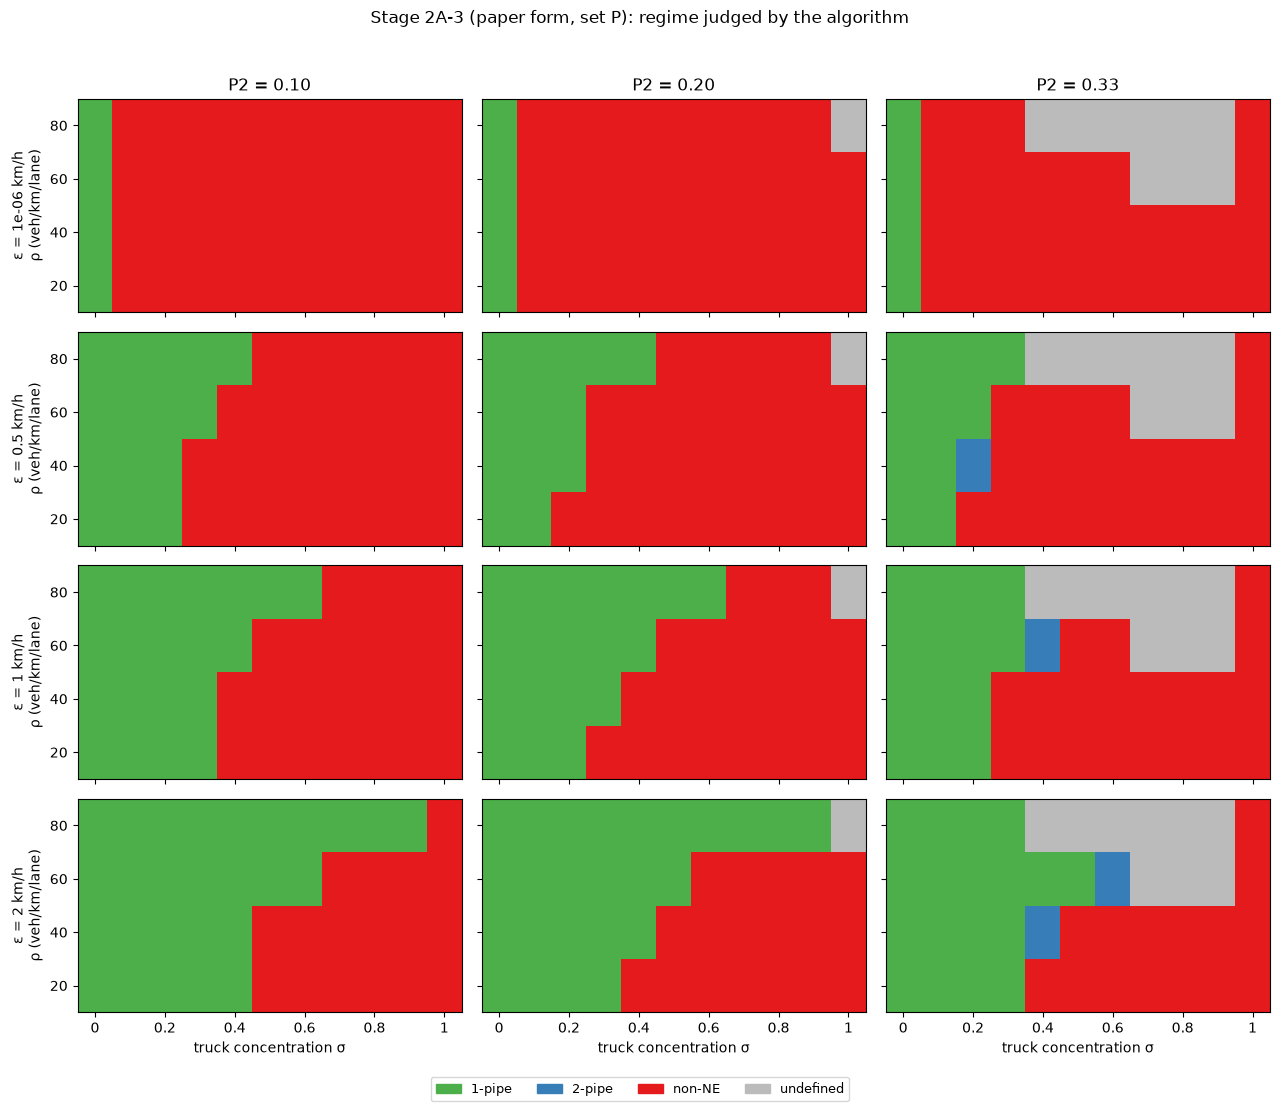

,rho_tot,P2,eps=1e-06,eps=0.5,eps=1,eps=2
0,20,0.100,0.1,0.3,0.4,0.5
1,20,0.200,0.1,0.2,0.3,0.4
2,20,0.333,0.1,0.2,0.3,0.4
3,40,0.100,0.1,0.3,0.4,0.5
4,40,0.200,0.1,0.3,0.4,0.5
5,40,0.333,0.1,0.2,0.3,0.4
6,60,0.100,0.1,0.4,0.5,0.7
7,60,0.200,0.1,0.3,0.5,0.6
8,60,0.333,0.1,0.3,0.4,0.6
9,80,0.100,0.1,0.5,0.7,1.0


In [6]:
REGIME_CODE = {'1-pipe': 0, '2-pipe': 1, 'non-NE': 2, 'undefined': 3}
REGIME_CMAP = ListedColormap(['#4daf4a', '#377eb8', '#e41a1c', '#bbbbbb'])


def plot_regime_map(df, rho_list, title, fname):
    fig, axes = plt.subplots(len(EPS_LIST), len(P2_LIST), figsize=(4.3 * len(P2_LIST), 2.6 * len(EPS_LIST)),
                             sharex=True, sharey=True)
    for a, eps in enumerate(EPS_LIST):
        for b, P2 in enumerate(P2_LIST):
            ax = axes[a, b]
            g = df[df['P2'] == round(P2, 3)]
            tab = g.pivot(index='rho_tot', columns='sigma', values=f'regime_{eps:g}').loc[rho_list]
            ax.imshow(tab.apply(lambda c: c.map(REGIME_CODE)).values.astype(float), origin='lower', cmap=REGIME_CMAP,
                      vmin=-0.5, vmax=3.5, aspect='auto')
            ax.set_xticks(range(len(tab.columns))[::2], [f"{s:g}" for s in tab.columns[::2]])
            ax.set_yticks(range(len(tab.index)), tab.index)
            if a == 0:
                ax.set_title(f"P2 = {P2:.2f}")
            if b == 0:
                ax.set_ylabel(f"ε = {eps:g} km/h\nρ (veh/km/lane)")
            if a == len(EPS_LIST) - 1:
                ax.set_xlabel("truck concentration σ")
    handles = [plt.Rectangle((0, 0), 1, 1, color=REGIME_CMAP(i)) for i in range(4)]
    fig.legend(handles, list(REGIME_CODE), loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=9)
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=150, bbox_inches='tight')
    plt.show()


def first_sigma_not_1pipe(df, rho_list):
    """(ρ, P2, ε) ごとに、1-pipe と判定されなくなる最小の σ（ずっと 1-pipe なら NaN）"""
    rows = []
    for rho in rho_list:
        for P2 in P2_LIST:
            g = df[(df['rho_tot'] == rho) & (df['P2'] == round(P2, 3))].sort_values('sigma')
            row = {'rho_tot': rho, 'P2': round(P2, 3)}
            for eps in EPS_LIST:
                not1 = g[g[f'regime_{eps:g}'] != '1-pipe']['sigma']
                row[f'eps={eps:g}'] = not1.min() if len(not1) else np.nan
            rows.append(row)
    return pd.DataFrame(rows)


plot_regime_map(df, RHO_TOT, "Stage 2A-3 (paper form, set P): regime judged by the algorithm", "stage2A3_paper_regime_map.png")
first_sigma_not_1pipe(df, RHO_TOT)

In [7]:
# 見た目がはっきりしているスナップショット（混合・完全分離）の正解と判定（ε = 2）
cols = ['rho_tot', 'P2', 'sigma', 'visual', 'label', 'u1_obs', 'u2_obs', 'u_1pipe', 'p1_star', 'p2_star', 's',
        'p2_actual', 'regime_2']
df[df['visual'] != '部分分離'][cols].round(3)

,rho_tot,P2,sigma,visual,label,u1_obs,u2_obs,u_1pipe,p1_star,p2_star,s,p2_actual,regime_2
0,20,0.100,0.0,混合,L1,61.319,61.319,61.319,0.614,0.698,-0.313,NaN,1-pipe
11,20,0.200,0.0,混合,L1,55.719,55.719,55.719,0.499,0.748,-0.247,NaN,1-pipe
22,20,0.333,0.0,混合,L1,49.644,49.644,49.644,0.377,0.799,-0.176,NaN,1-pipe
32,20,0.333,1.0,完全分離,L4,84.513,31.670,49.644,0.377,0.799,-0.176,0.333,non-NE
33,40,0.100,0.0,混合,L1,36.200,36.200,36.200,0.796,0.242,-0.038,NaN,1-pipe
44,40,0.200,0.0,混合,L1,31.684,31.684,31.684,0.642,0.400,-0.042,NaN,1-pipe
55,40,0.333,0.0,混合,L1,27.208,27.208,27.208,0.479,0.557,-0.036,NaN,1-pipe
65,40,0.333,1.0,完全分離,L4,42.596,14.647,27.208,0.479,0.557,-0.036,0.333,non-NE
66,60,0.100,0.0,混合,L1,21.551,21.551,21.551,0.813,0.200,-0.013,NaN,1-pipe
77,60,0.200,0.0,混合,L1,19.221,19.221,19.221,0.656,0.364,-0.021,NaN,1-pipe


## 5. OV スケール形で同じことをする
2A-1 §8 と同じ設定：V_ij(h) = V_ii(a_ij·h)、a2, b1 = セットP、vmax・車長・形は既定値（仮置き）、ρ = 30〜50。
アルゴリズム側にも正解の OV関数を渡す（推定しない）。Eq.7 と p* は src が論文形専用なのでここで書く（2A-1 §8 と同じ関数）

In [8]:
OV_NOMINAL = make_ov_nominal(form='scale', scale={(1, 2): A2, (2, 1): B1})
RHO_TOT_OV = [30, 35, 40, 50]
V_HI_OV = min(OV_NOMINAL['vmax'].values()) * (1 - 1e-9)


def eq7_speed_general(nominal, a2, b1, rho1, rho2, v_lo, v_hi):
    """印刷版 Eq.7 の u*（2A-1 §8 と同じ）。R_i(u) は nominal の自クラスの関数"""
    rho = rho1 + rho2
    def f(u):
        R1 = R_eq(nominal, CAR, CAR, u)
        R2 = R_eq(nominal, TRUCK, TRUCK, u)
        return (rho1 / R1 * (rho1 + rho2 / a2) + rho2 / R2 * (rho1 / b1 + rho2)) / rho - 1.0
    if f(v_lo) > 0 or f(v_hi) < 0:
        return np.nan
    u = brentq(f, v_lo, v_hi, xtol=1e-12)
    return np.nan if u >= v_hi - 1e-9 else u


df_obs_ov = build_snapshots(OV_NOMINAL, RHO_TOT_OV)
print(f"スナップショット {len(df_obs_ov)} 枚、速度が解けない: {df_obs_ov[['u1_obs', 'u2_obs']].isna().any(axis=1).sum()} 枚")
df_obs_ov['u_1pipe'] = [eq7_speed_general(OV_NOMINAL, A2, B1, r['rho1'], r['rho2'], 1e-6, V_HI_OV)
                        for _, r in df_obs_ov.iterrows()]
df_ov = df_obs_ov.copy()
df_ov['p1_star'] = df_ov['rho1'] / R_eq(OV_NOMINAL, CAR, CAR, df_ov['u_1pipe'].values)
df_ov['p2_star'] = df_ov['rho2'] / R_eq(OV_NOMINAL, TRUCK, TRUCK, df_ov['u_1pipe'].values)
df_ov = compute_cooperation_surplus(df_ov)
df_ov = add_truth_label(df_ov)
df_ov['du1'] = df_ov['u1_obs'] - df_ov['u_1pipe']
df_ov['du2'] = df_ov['u2_obs'] - df_ov['u_1pipe']

regimes_ov, coop_ov = {}, {}
for eps in EPS_LIST:
    out = check_cooperation_existence(classify_traffic_regime(df_ov, eps_kmh=eps))
    regimes_ov[eps], coop_ov[eps] = out['regime'], out['coop_exists']
    df_ov[f'regime_{eps:g}'] = out['regime']
    df_ov[f'coop_{eps:g}'] = out['coop_exists']

mix = df_ov['visual'] == '混合'
print(f"\nσ=0 での |ũ − u*| の最大値（0 のはず）: {df_ov.loc[mix, ['du1', 'du2']].abs().max().max():.1e} km/h")
print(f"s の範囲: {df_ov['s'].min():.4f} 〜 {df_ov['s'].max():.4f}")
df_ov.to_csv(OUT / "stage2A3_OV.csv", index=False, encoding='utf-8-sig')

スナップショット 132 枚、速度が解けない: 0 枚
協力余剰sを計算: 132スナップショット中、132件で計算完了（うちs>0: 132件）
交通状態を判定(eps: 車 0.00, トラック 0.00 km/h): 判定対象 132件 (対象外 undefined: 0件)
      2-pipe: 0件 (0.00%)
      1-pipe: 12件 (9.09%)
      non-NE: 120件 (90.91%)
  Pcoop = 0.00% (論文: 13.83%)
  平均s: 2-pipe = nan, 1-pipe = 0.0426 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 132件
  s>0             : 132件 (100.00%)
  2-pipe          : 0件 (0.00%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 0件 (0.00%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 0件 (nan% of 2-pipe)  ← 命題1と不整合
交通状態を判定(eps: 車 0.50, トラック 0.50 km/h): 判定対象 132件 (対象外 undefined: 0件)
      2-pipe: 1件 (0.76%)
      1-pipe: 30件 (22.73%)
      non-NE: 101件 (76.52%)
  Pcoop = 0.76% (論文: 13.83%)
  平均s: 2-pipe = 0.0551, 1-pipe = 0.0407 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 132件
  s>0             : 132件 (100.00%)
  2-pipe          : 1件 (0.76%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 1件 (0.76%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 0件 (0.00% of 2-pipe)  ← 命題1と不整合
交通状態を判定(eps: 車 1.00, トラック 1.00 km/h): 判定対象 132件 (対象外 undefi

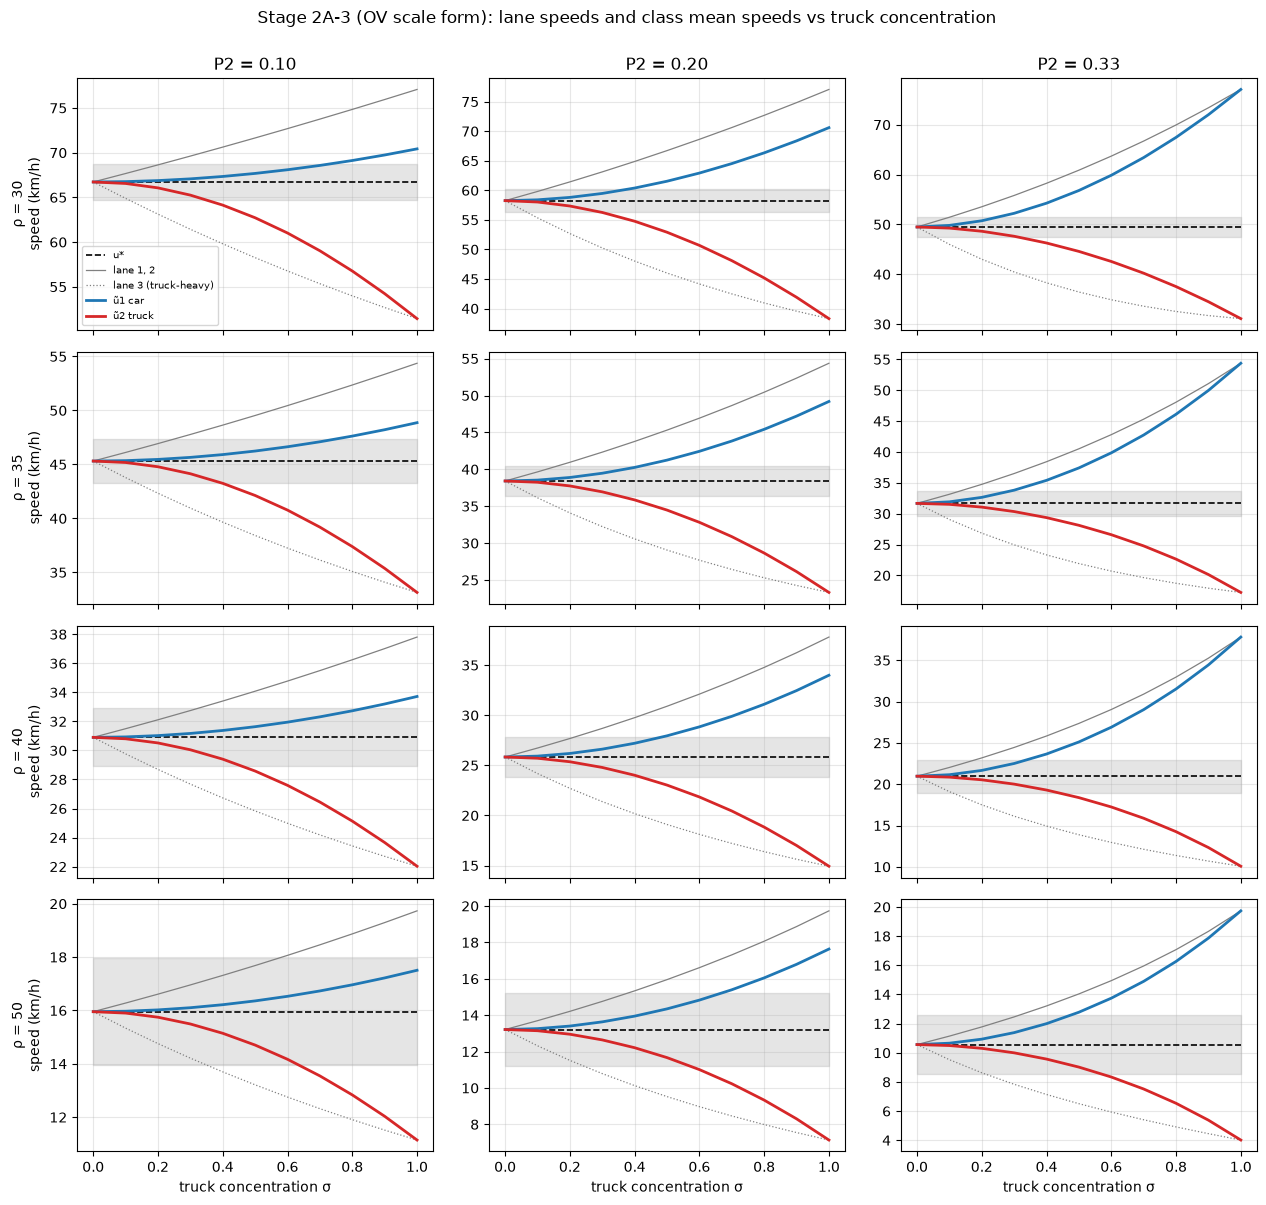

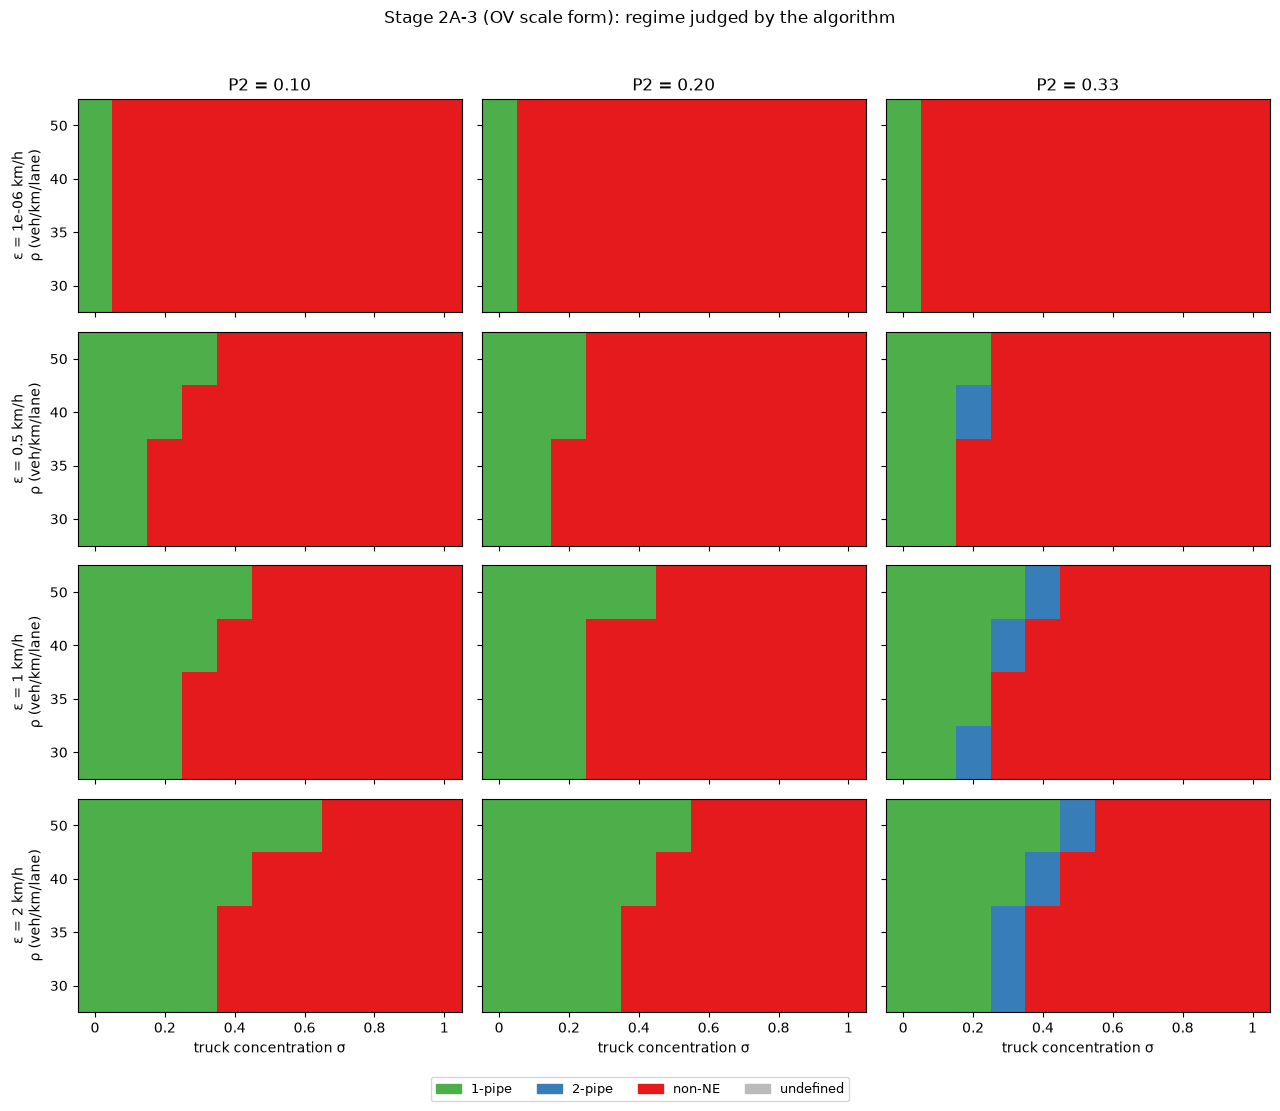

,rho_tot,P2,eps=1e-06,eps=0.5,eps=1,eps=2
0,30,0.100,0.1,0.2,0.3,0.4
1,30,0.200,0.1,0.2,0.3,0.4
2,30,0.333,0.1,0.2,0.2,0.3
3,35,0.100,0.1,0.2,0.3,0.4
4,35,0.200,0.1,0.2,0.3,0.4
5,35,0.333,0.1,0.2,0.3,0.3
6,40,0.100,0.1,0.3,0.4,0.5
7,40,0.200,0.1,0.3,0.3,0.5
8,40,0.333,0.1,0.2,0.3,0.4
9,50,0.100,0.1,0.4,0.5,0.7


In [9]:
plot_mechanism(df_ov, RHO_TOT_OV, "Stage 2A-3 (OV scale form): lane speeds and class mean speeds vs truck concentration",
               "stage2A3_OV_mechanism.png")
plot_regime_map(df_ov, RHO_TOT_OV, "Stage 2A-3 (OV scale form): regime judged by the algorithm", "stage2A3_OV_regime_map.png")
first_sigma_not_1pipe(df_ov, RHO_TOT_OV)

In [10]:
# 見た目がはっきりしているスナップショットの正解と判定（ε = 2）。OV形では s > 0 なので、2-pipe なら「協力あり」
cols_ov = cols + ['coop_2']
df_ov[df_ov['visual'] != '部分分離'][cols_ov].round(3)

,rho_tot,P2,sigma,visual,label,u1_obs,u2_obs,u_1pipe,p1_star,p2_star,s,p2_actual,regime_2,coop_2
0,30,0.100,0.0,混合,L2,66.724,66.724,66.724,0.840,0.131,0.029,NaN,1-pipe,False
11,30,0.200,0.0,混合,L2,58.256,58.256,58.256,0.705,0.246,0.049,NaN,1-pipe,False
22,30,0.333,0.0,混合,L2,49.487,49.487,49.487,0.551,0.385,0.064,NaN,1-pipe,False
32,30,0.333,1.0,完全分離,L4,77.072,31.107,49.487,0.551,0.385,0.064,0.333,non-NE,False
33,35,0.100,0.0,混合,L2,45.313,45.313,45.313,0.840,0.131,0.029,NaN,1-pipe,False
44,35,0.200,0.0,混合,L2,38.420,38.420,38.420,0.704,0.248,0.048,NaN,1-pipe,False
55,35,0.333,0.0,混合,L2,31.669,31.669,31.669,0.549,0.391,0.061,NaN,1-pipe,False
65,35,0.333,1.0,完全分離,L4,54.371,17.241,31.669,0.549,0.391,0.061,0.333,non-NE,False
66,40,0.100,0.0,混合,L2,30.902,30.902,30.902,0.839,0.133,0.028,NaN,1-pipe,False
77,40,0.200,0.0,混合,L2,25.833,25.833,25.833,0.702,0.254,0.045,NaN,1-pipe,False
